Week 5 SVM libraries loaded. Ready to draw some boundaries!
Target variable: price_trend (1 = Above Median, 0 = Below Median)
Features we are using: ['open', 'high', 'low', 'volume']

--- Linear SVM Results ---
              precision    recall  f1-score   support

           0       0.98      0.99      0.98       615
           1       0.98      0.98      0.98       581

    accuracy                           0.98      1196
   macro avg       0.98      0.98      0.98      1196
weighted avg       0.98      0.98      0.98      1196


--- RBF Kernel SVM Results ---
              precision    recall  f1-score   support

           0       0.98      0.99      0.99       615
           1       0.99      0.98      0.98       581

    accuracy                           0.98      1196
   macro avg       0.98      0.98      0.98      1196
weighted avg       0.98      0.98      0.98      1196



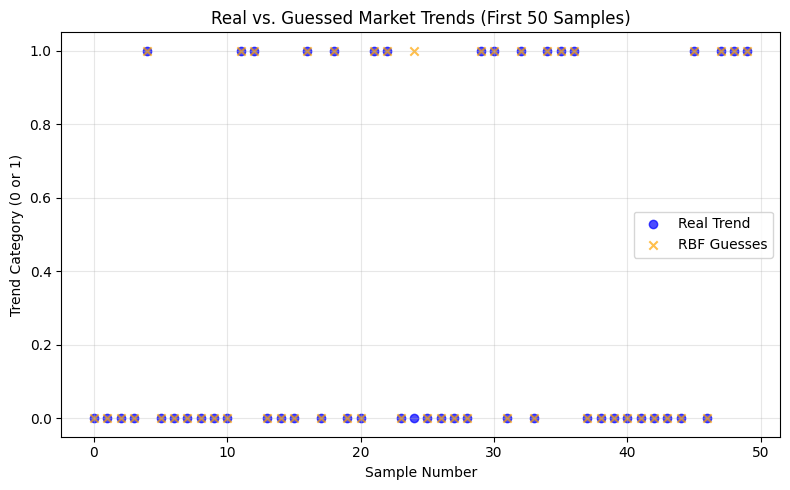

In [1]:
# Step 1: Get the libraries ready for Week 5 (Support Vector Machines)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import classification_report

print("Week 5 SVM libraries loaded. Ready to draw some boundaries!")

# Step 2: Load our gas dataset from GitHub
link_gas = "https://raw.githubusercontent.com/JSFranco-DS/DX699S/main/Natural_Gas_data.csv"
df_gas = pd.read_csv(link_gas)

# SVM classification is easier to visualize than regression, so let's make a binary target.
# We will say 1 if the close price is above the median (average), and 0 if it is below.
median_price = df_gas['close'].median()
df_gas['price_trend'] = (df_gas['close'] > median_price).astype(int)

y_name = 'price_trend'
# Just picking a few specific numeric columns to keep the model fast and simple
num_cols = ['open', 'high', 'low', 'volume']

# Clean out any missing values
clean_df = df_gas[[y_name] + num_cols].dropna()
X = clean_df[num_cols]
y = clean_df[y_name]

print("Target variable:", y_name, "(1 = Above Median, 0 = Below Median)")
print("Features we are using:", X.columns.tolist())

# Step 3: Split into Train and Test, then Scale
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Scaling is super important for SVMs! If we don't scale, the distance math gets really confused.
my_scaler = StandardScaler()
X_train_scaled = my_scaler.fit_transform(X_train)
X_test_scaled = my_scaler.transform(X_test)

# Step 4: Train a Support Vector Classifier (SVC) with a straight line (Linear Kernel)
my_linear_svm = SVC(kernel='linear', C=1.0)
my_linear_svm.fit(X_train_scaled, y_train)

linear_guesses = my_linear_svm.predict(X_test_scaled)
print("\n--- Linear SVM Results ---")
print(classification_report(y_test, linear_guesses))

# Step 5: Apply the Kernel Trick (RBF Kernel) and Regularization (C)
# The RBF kernel helps us draw curved boundaries when a straight line doesn't work.
# The 'C' parameter controls strictness: higher C means we penalize mistakes more heavily.
my_rbf_svm = SVC(kernel='rbf', C=10.0, gamma='scale')
my_rbf_svm.fit(X_train_scaled, y_train)

rbf_guesses = my_rbf_svm.predict(X_test_scaled)
print("\n--- RBF Kernel SVM Results ---")
print(classification_report(y_test, rbf_guesses))

# Step 6: Draw a graph to compare real trends vs what our RBF model guessed
plt.figure(figsize=(8, 5))

# Plotting just the first 50 test samples so it doesn't look too crowded
plt.scatter(range(50), y_test[:50], color='blue', label='Real Trend', marker='o', alpha=0.7)
plt.scatter(range(50), rbf_guesses[:50], color='orange', label='RBF Guesses', marker='x', alpha=0.7)

plt.title("Real vs. Guessed Market Trends (First 50 Samples)")
plt.xlabel("Sample Number")
plt.ylabel("Trend Category (0 or 1)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()